# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
temps = pd.read_csv('data/temps.csv')
temps

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41
...,...,...,...,...,...,...,...,...,...
343,2016,12,27,Tues,42,42,45.2,47,47
344,2016,12,28,Wed,42,47,45.3,48,58
345,2016,12,29,Thurs,47,48,45.3,48,65
346,2016,12,30,Fri,48,48,45.4,57,42


### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [6]:
temps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    object 
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), object(1)
memory usage: 24.6+ KB


In [7]:
temps.describe()

,year,month,day,temp_2,temp_1,average,actual,friend
count,348.0,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000
mean,2016.0,6.477011,15.514368,62.652299,62.701149,59.760632,62.543103,60.034483
std,0.0,3.498380,8.772982,12.165398,12.120542,10.527306,11.794146,15.626179
min,2016.0,1.000000,1.000000,35.000000,35.000000,45.100000,35.000000,28.000000
25%,2016.0,3.000000,8.000000,54.000000,54.000000,49.975000,54.000000,47.750000
50%,2016.0,6.000000,15.000000,62.500000,62.500000,58.200000,62.500000,60.000000
75%,2016.0,10.000000,23.000000,71.000000,71.000000,69.025000,71.000000,71.000000
max,2016.0,12.000000,31.000000,117.000000,117.000000,77.400000,92.000000,95.000000


In [5]:
temps['week'].value_counts()

week
Tues     52
Fri      50
Sat      50
Sun      49
Mon      49
Wed      49
Thurs    49
Name: count, dtype: int64

In [8]:
# Conversión de week de str a int
def map_weekday(nom):
    weekdays = {
        "Mon": 0,
        "Tues": 1,
        "Wed": 2,
        "Thurs": 3,
        "Fri": 4,
        "Sat": 5,
        "Sun": 6
    }
    if nom in weekdays.keys():
        return weekdays[nom]
    else:
        return -999


In [17]:
temps['week_num'] = temps['week'].apply(map_weekday)

In [18]:
temps

,year,month,day,week,temp_2,temp_1,average,actual,friend,week_num
0,2016,1,1,Fri,45,45,45.6,45,29,4
1,2016,1,2,Sat,44,45,45.7,44,61,5
2,2016,1,3,Sun,45,44,45.8,41,56,6
3,2016,1,4,Mon,44,41,45.9,40,53,0
4,2016,1,5,Tues,41,40,46.0,44,41,1
...,...,...,...,...,...,...,...,...,...,...
343,2016,12,27,Tues,42,42,45.2,47,47,1
344,2016,12,28,Wed,42,47,45.3,48,58,2
345,2016,12,29,Thurs,47,48,45.3,48,65,3
346,2016,12,30,Fri,48,48,45.4,57,42,4


In [20]:
temps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   year      348 non-null    int64  
 1   month     348 non-null    int64  
 2   day       348 non-null    int64  
 3   week      348 non-null    object 
 4   temp_2    348 non-null    int64  
 5   temp_1    348 non-null    int64  
 6   average   348 non-null    float64
 7   actual    348 non-null    int64  
 8   friend    348 non-null    int64  
 9   week_num  348 non-null    int64  
dtypes: float64(1), int64(8), object(1)
memory usage: 27.3+ KB


In [21]:
temps.describe()

,year,month,day,temp_2,temp_1,average,actual,friend,week_num
count,348.0,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000
mean,2016.0,6.477011,15.514368,62.652299,62.701149,59.760632,62.543103,60.034483,2.991379
std,0.0,3.498380,8.772982,12.165398,12.120542,10.527306,11.794146,15.626179,2.000702
min,2016.0,1.000000,1.000000,35.000000,35.000000,45.100000,35.000000,28.000000,0.000000
25%,2016.0,3.000000,8.000000,54.000000,54.000000,49.975000,54.000000,47.750000,1.000000
50%,2016.0,6.000000,15.000000,62.500000,62.500000,58.200000,62.500000,60.000000,3.000000
75%,2016.0,10.000000,23.000000,71.000000,71.000000,69.025000,71.000000,71.000000,5.000000
max,2016.0,12.000000,31.000000,117.000000,117.000000,77.400000,92.000000,95.000000,6.000000


In [22]:
temps['week_num'].value_counts()

week_num
1    52
4    50
5    50
6    49
0    49
2    49
3    49
Name: count, dtype: int64

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


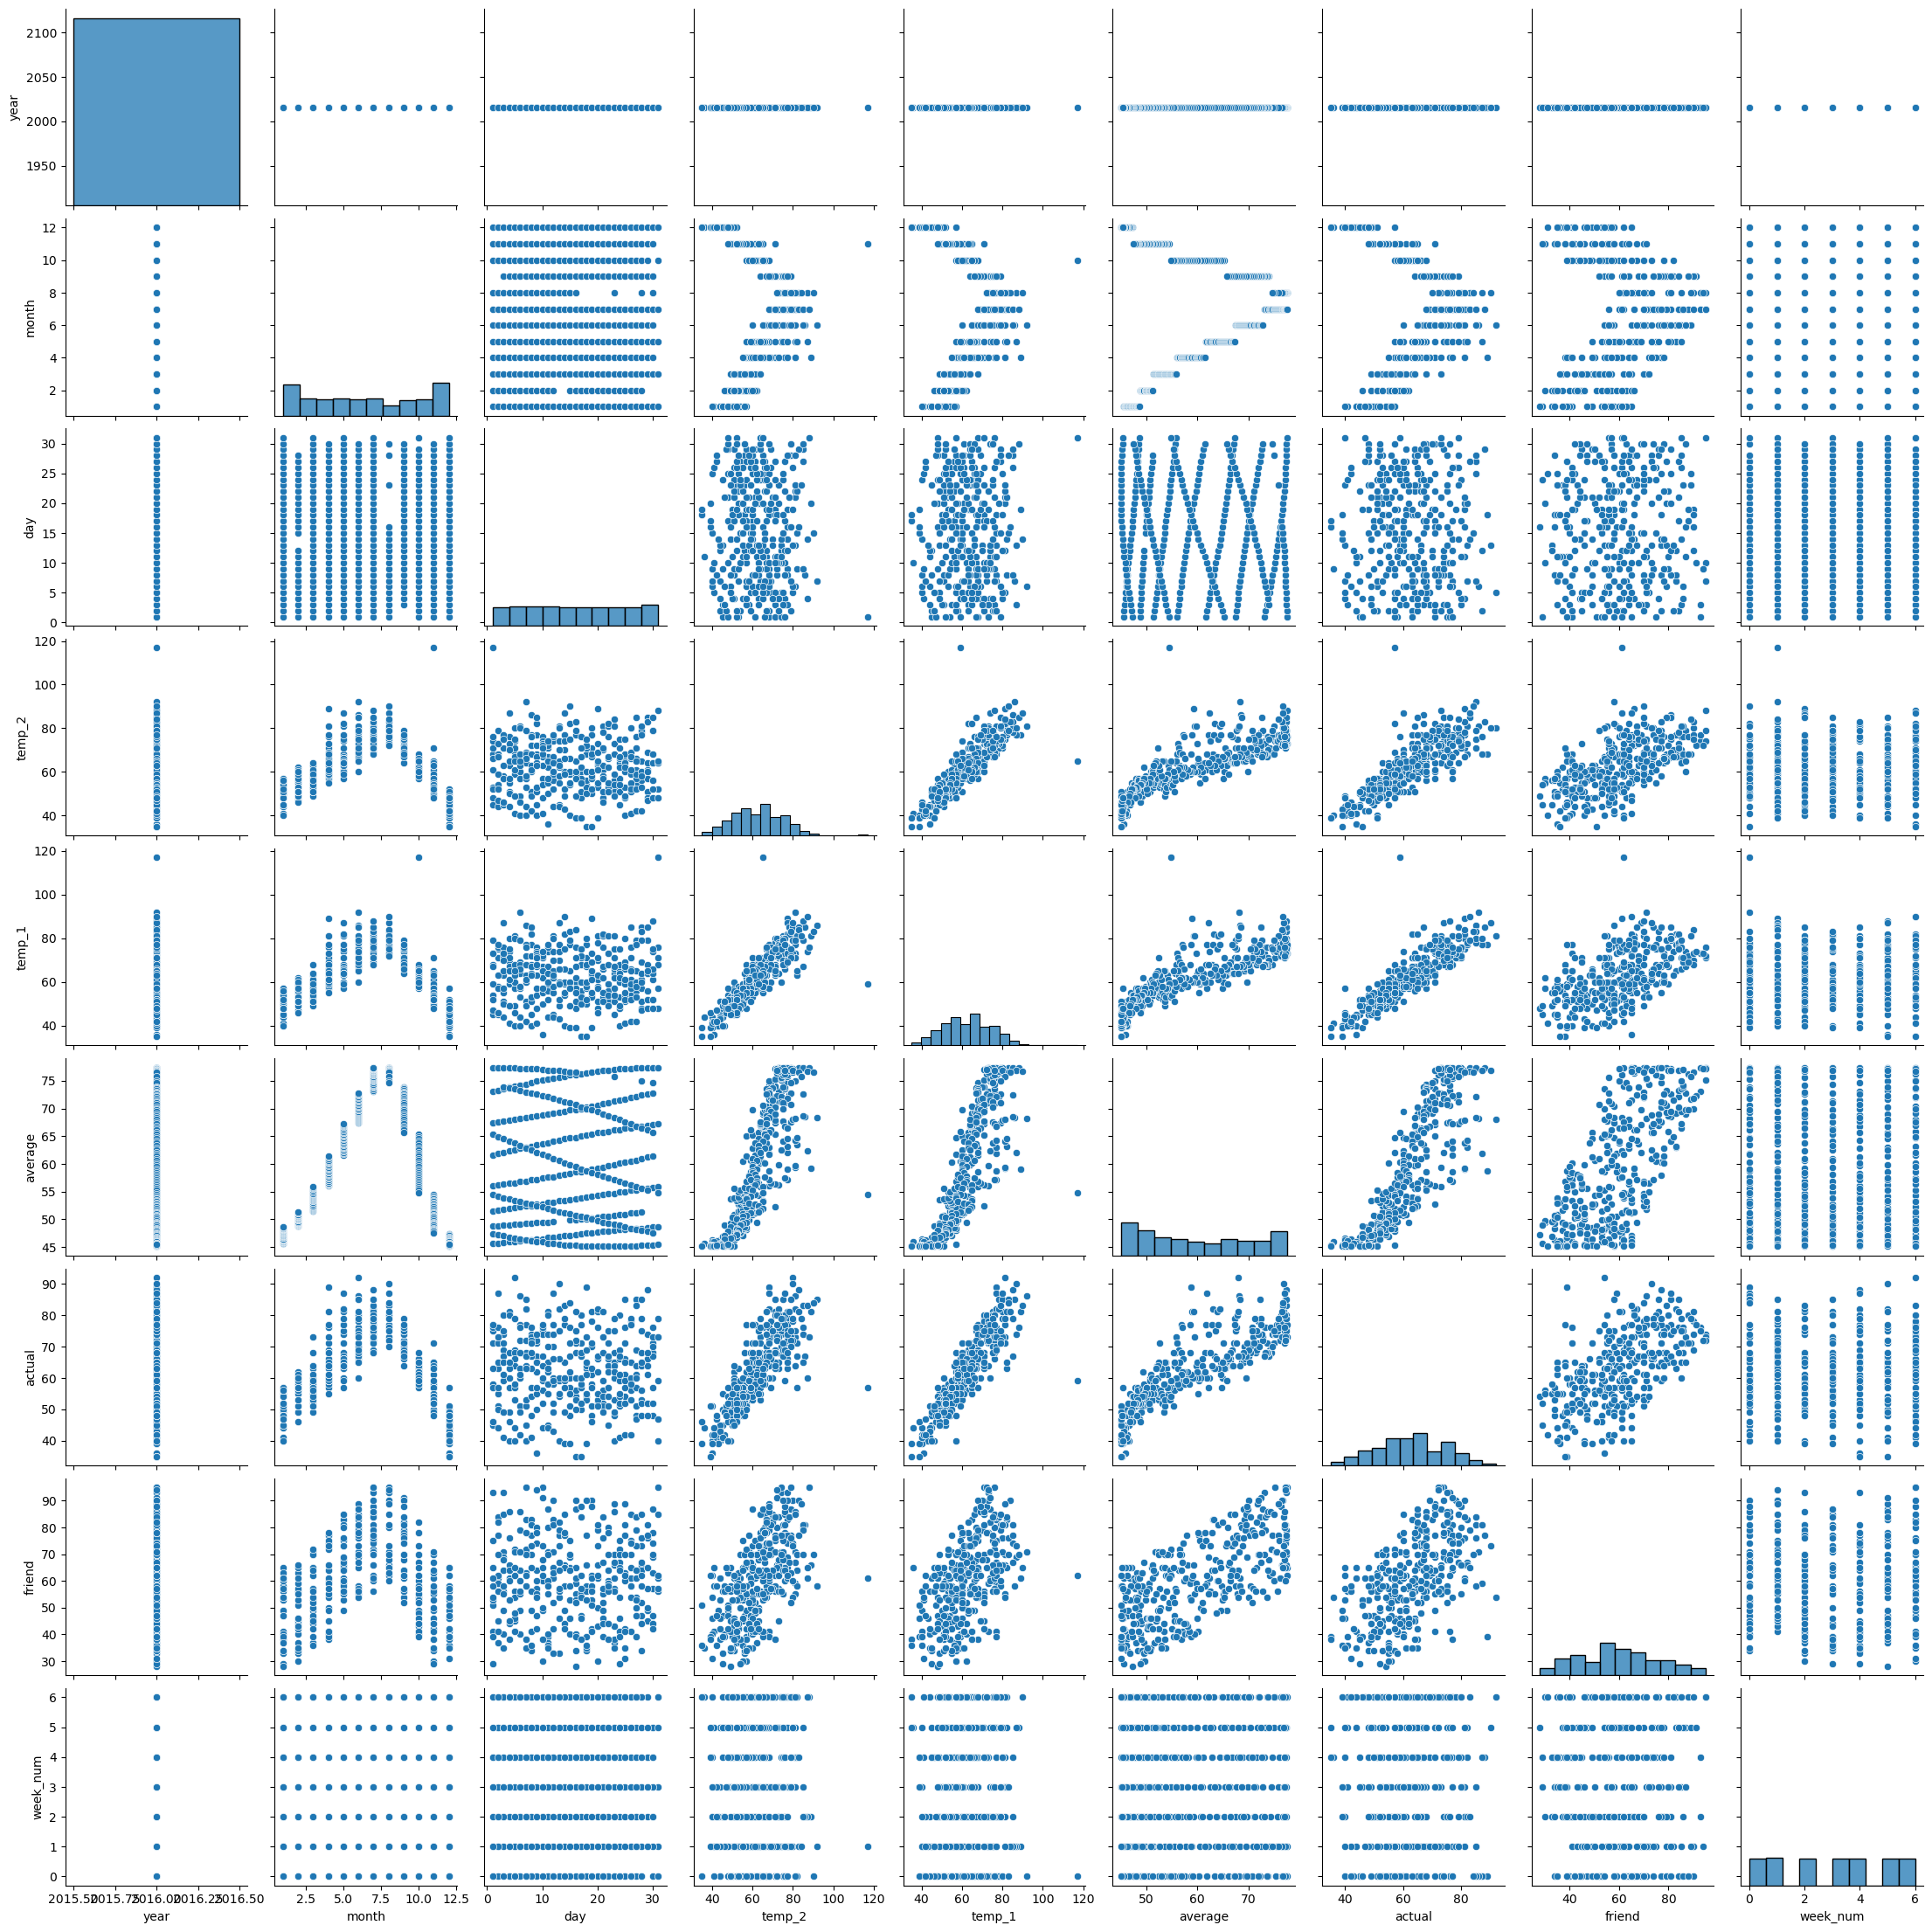

In [23]:
sns.pairplot(temps);

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


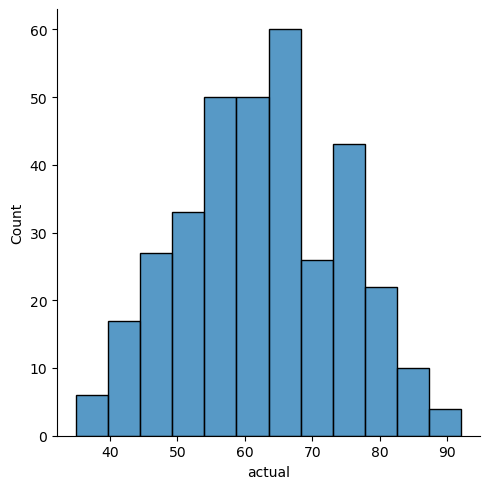

In [25]:
sns.displot(temps['actual'])

In [37]:
m_corr = temps.corr(method='pearson', numeric_only=True)

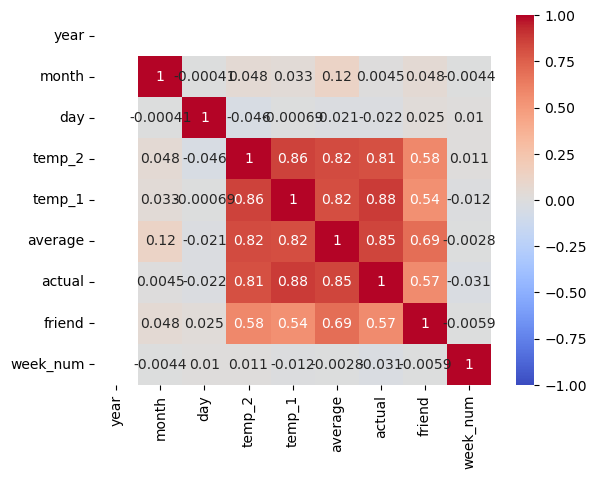

In [38]:
sns.heatmap(m_corr, annot=True, vmin=-1, vmax=1, cmap='coolwarm');

### 3. Selecciona variables y divide en train y test

In [31]:
temps.columns

Index(['year', 'month', 'day', 'week', 'temp_2', 'temp_1', 'average', 'actual',
       'friend', 'week_num'],
      dtype='object')

In [32]:
X = temps[['month', 'day', 'temp_2', 'temp_1', 'average', 'friend', 'week_num']]
y = temps['actual']

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

### 4. Entrena el modelo


In [40]:
from sklearn.tree import DecisionTreeRegressor

In [41]:
# tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [42]:
y_pred_train = tree_reg.predict(X_train)
y_pred_test = tree_reg.predict(X_test)

In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

In [44]:
print('Coef determ R2 test:', tree_reg.score(X_test, y_test))
print('Coef determ R2 test:', r2_score(y_test, y_pred_test))
print('MAE test:', mean_absolute_error(y_test, y_pred_test))
print('MSE test:', mean_squared_error(y_test, y_pred_test))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, y_pred_test)))
print('MAPE test:', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_test))
print()
print('Coef determ R2 train:', tree_reg.score(X_train, y_train))
print('Coef determ R2 train:', r2_score(y_train, y_pred_train))
print('MAE train:', mean_absolute_error(y_train, y_pred_train))
print('MSE train:', mean_squared_error(y_train, y_pred_train))
print('RMSE train:', np.sqrt(mean_squared_error(y_train, y_pred_train)))
print('MAPE train:', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_train))

Coef determ R2 test: 0.7438640636129048
Coef determ R2 test: 0.7438640636129048
MAE test: 4.5
MSE test: 35.81428571428572
RMSE test: 5.984503798502071
MAPE test: 0.07173246502201502

Coef determ R2 train: 1.0
Coef determ R2 train: 1.0
MAE train: 0.0
MSE train: 0.0
RMSE train: 0.0
MAPE train: 0.0


### 6. Representa el árbol de decisión

In [45]:
import sklearn

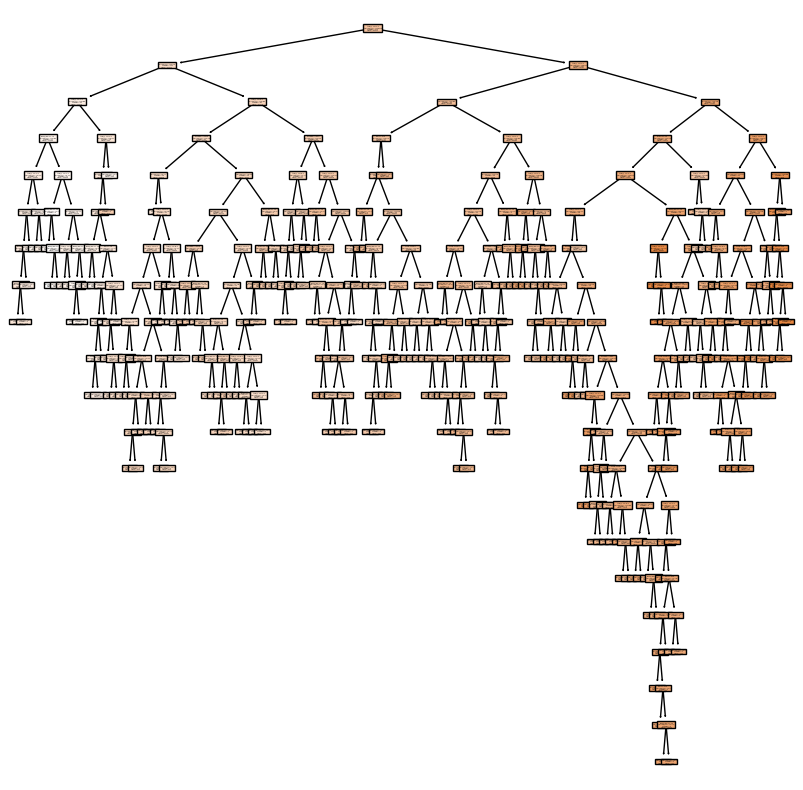

In [48]:
plt.figure(figsize=(10,10))
sklearn.tree.plot_tree(tree_reg,
               feature_names=list(X.columns),
                class_names=None,
               filled = True);

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [50]:
tree_reg2 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_reg2.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=42)

### 8. Vuelve a evaluar tu modelo

In [ ]:
y_pred_train2 = tree_reg2.predict(X_train)
y_pred_test2 = tree_reg2.predict(X_test)

In [53]:
print('Coef determ R2 test:', tree_reg2.score(X_test, y_test))
print('Coef determ R2 test:', r2_score(y_test, y_pred_test2))
print('MAE test:', mean_absolute_error(y_test, y_pred_test2))
print('MSE test:', mean_squared_error(y_test, y_pred_test2))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, y_pred_test2)))
print('MAPE test:', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_test2))
print()
print('Coef determ R2 train:', tree_reg2.score(X_train, y_train))
print('Coef determ R2 train:', r2_score(y_train, y_pred_train2))
print('MAE train:', mean_absolute_error(y_train, y_pred_train2))
print('MSE train:', mean_squared_error(y_train, y_pred_train2))
print('RMSE train:', np.sqrt(mean_squared_error(y_train, y_pred_train2)))
print('MAPE train:', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_train2))

Coef determ R2 test: 0.7786776796296856
Coef determ R2 test: 0.7786776796296856
MAE test: 4.267242249556827
MSE test: 30.946461197509944
RMSE test: 5.5629543587476915
MAPE test: 0.0674392768128964

Coef determ R2 train: 0.8397458755018086
Coef determ R2 train: 0.8397458755018086
MAE train: 3.675752083754991
MSE train: 22.14996536445183
RMSE train: 4.706374970659672
MAPE train: 0.05874668452706153


### 9. Vuelve a representar su árbol

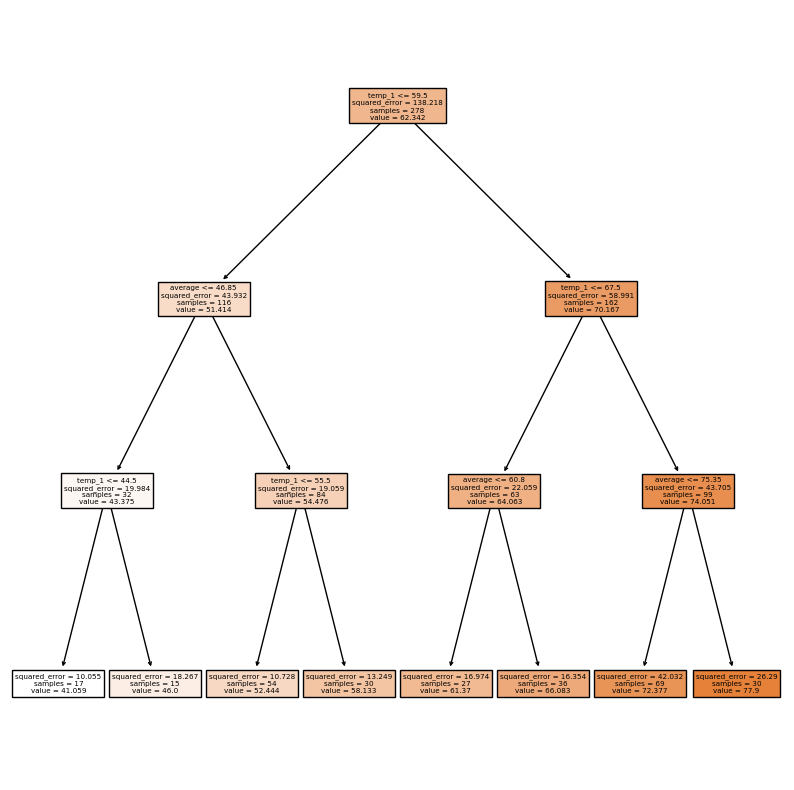

In [54]:
plt.figure(figsize=(10,10))
sklearn.tree.plot_tree(tree_reg2,
               feature_names=list(X.columns),
                class_names=None,
               filled = True);

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [55]:
from sklearn.model_selection import GridSearchCV

In [58]:
tree_reg3 = DecisionTreeRegressor(random_state=42)

In [60]:
param_grid = {
    'criterion': ['squared_error', 'friedman_mse', 'absolute_error'],       # Splitting criteria
    'max_depth': [None, 2, 3, 4, 6, 8, 10],    # Tree depth
    'min_samples_split': [2, 5, 10],        # Minimum samples to split
    'min_samples_leaf': [1, 2, 4]           # Minimum samples per leaf
}

In [61]:
grid_search = GridSearchCV(
    estimator=tree_reg3,
    param_grid=param_grid,
    scoring='r2',           # Metric to optimize
    cv=10,                   # 10-fold cross-validation
    n_jobs=-1,              # Use all CPU cores
    verbose=1               # Show progress
)

In [62]:
grid_search.fit(X_train, y_train)

Fitting 10 folds for each of 189 candidates, totalling 1890 fits


GridSearchCV(cv=10, estimator=DecisionTreeRegressor(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['squared_error', 'friedman_mse',
                                       'absolute_error'],
                         'max_depth': [None, 2, 3, 4, 6, 8, 10],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2', verbose=1)

In [67]:
print("Mejores parámetros:", grid_search.best_params_)

Mejores parámetros: {'criterion': 'absolute_error', 'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}


In [68]:
tree_reg3_best = grid_search.best_estimator_
y_pred_train3 = tree_reg3_best.predict(X_train)
y_pred_test3 = tree_reg3_best.predict(X_test)

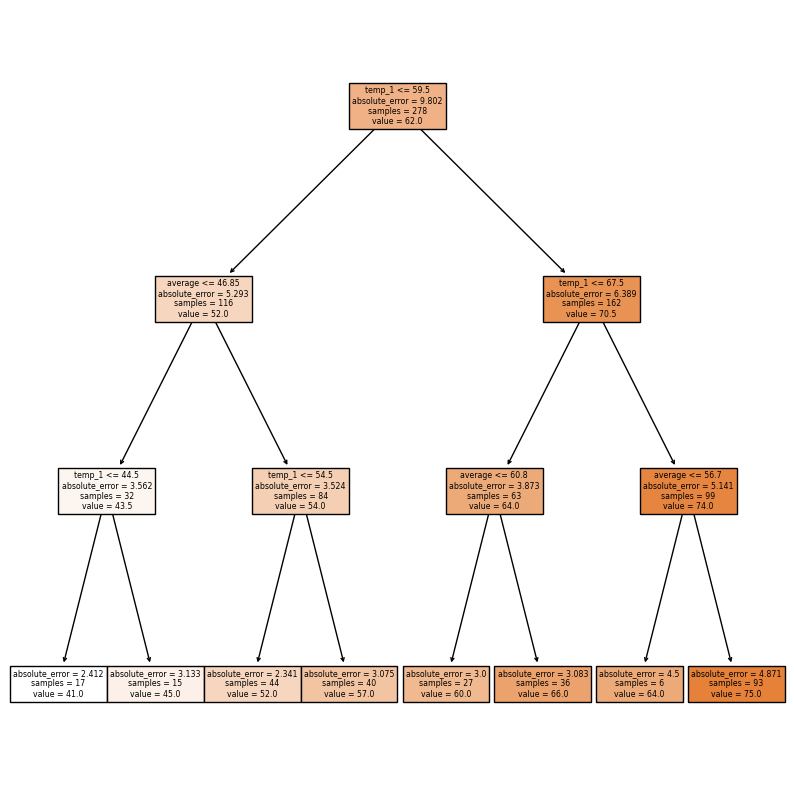

In [73]:
plt.figure(figsize=(10,10))
sklearn.tree.plot_tree(tree_reg3_best,
               feature_names=list(X.columns),
                class_names=None,
               filled = True);

In [70]:
print('Coef determ R2 test:', tree_reg3_best.score(X_test, y_test))
print('Coef determ R2 test:', r2_score(y_test, y_pred_test3))
print('MAE test:', mean_absolute_error(y_test, y_pred_test3))
print('MSE test:', mean_squared_error(y_test, y_pred_test3))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, y_pred_test3)))
print('MAPE test:', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_test3))
print()
print('Coef determ R2 train:', tree_reg3_best.score(X_train, y_train))
print('Coef determ R2 train:', r2_score(y_train, y_pred_train3))
print('MAE train:', mean_absolute_error(y_train, y_pred_train3))
print('MSE train:', mean_squared_error(y_train, y_pred_train3))
print('RMSE train:', np.sqrt(mean_squared_error(y_train, y_pred_train3)))
print('MAPE train:', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_train3))

Coef determ R2 test: 0.7723690202351623
Coef determ R2 test: 0.7723690202351623
MAE test: 4.485714285714286
MSE test: 31.82857142857143
RMSE test: 5.641681613541429
MAPE test: 0.07035247519634842

Coef determ R2 train: 0.8337520587162298
Coef determ R2 train: 0.8337520587162298
MAE train: 3.5467625899280577
MSE train: 22.97841726618705
RMSE train: 4.793580839642432
MAPE train: 0.056449001180634985


### 11. Obten el `feature_importances` de cada variable en el último modelo

In [72]:
importances = tree_reg3_best.feature_importances_
importances

array([0.        , 0.        , 0.        , 0.83611271, 0.16388729,
       0.        , 0.        ])

### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

In [74]:
temps['T_gt_59F'] = np.where(temps['actual']>59, 1, 0)
temps

,year,month,day,week,temp_2,temp_1,average,actual,friend,week_num,T_gt_59F
0,2016,1,1,Fri,45,45,45.6,45,29,4,0
1,2016,1,2,Sat,44,45,45.7,44,61,5,0
2,2016,1,3,Sun,45,44,45.8,41,56,6,0
3,2016,1,4,Mon,44,41,45.9,40,53,0,0
4,2016,1,5,Tues,41,40,46.0,44,41,1,0
...,...,...,...,...,...,...,...,...,...,...,...
343,2016,12,27,Tues,42,42,45.2,47,47,1,0
344,2016,12,28,Wed,42,47,45.3,48,58,2,0
345,2016,12,29,Thurs,47,48,45.3,48,65,3,0
346,2016,12,30,Fri,48,48,45.4,57,42,4,0


In [75]:
temps['T_gt_59F'].value_counts()

T_gt_59F
1    204
0    144
Name: count, dtype: int64

In [76]:
y2 = temps['T_gt_59F']

In [77]:
from sklearn.tree import DecisionTreeClassifier

In [82]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X, y2, test_size=0.2, random_state=42)

In [83]:
tree_clf = DecisionTreeClassifier(random_state=42)

In [84]:
param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],  # Classification criteria
    'max_depth': [None, 2, 3, 4, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [85]:
grid_search = GridSearchCV(
    estimator=tree_clf,
    param_grid=param_grid,
    scoring='accuracy',  # Optimize for accuracy
    cv=10,
    n_jobs=-1,
    verbose=1
)

In [86]:
grid_search.fit(X2_train, y2_train)

Fitting 10 folds for each of 189 candidates, totalling 1890 fits


GridSearchCV(cv=10, estimator=DecisionTreeClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [None, 2, 3, 4, 6, 8, 10],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy', verbose=1)

In [87]:
print("Mejores parámetros:", grid_search.best_params_)

Mejores parámetros: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [89]:
tree_clf_best = grid_search.best_estimator_
y2_pred_train = tree_clf_best.predict(X2_train)
y2_pred_test = tree_clf_best.predict(X2_test)

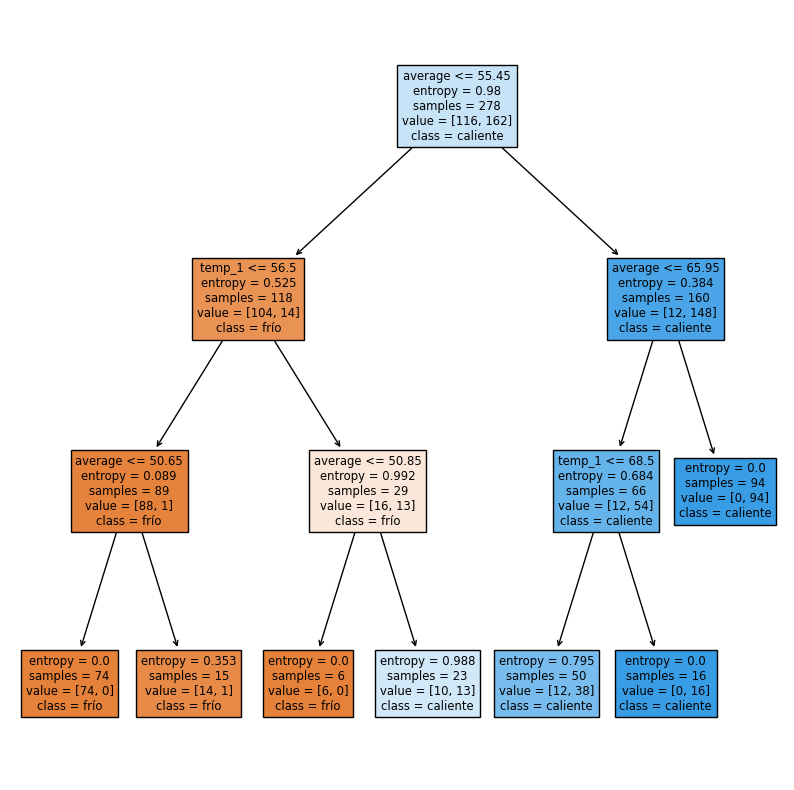

In [95]:
plt.figure(figsize=(10,10))
sklearn.tree.plot_tree(tree_clf_best,
               feature_names=list(X.columns),
                class_names=['frío', 'caliente'],
               filled = True);

In [96]:
importances = tree_clf_best.feature_importances_
importances

array([0.        , 0.        , 0.        , 0.15002178, 0.84997822,
       0.        , 0.        ])

In [97]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, classification_report

[[20  8]
 [ 1 41]]


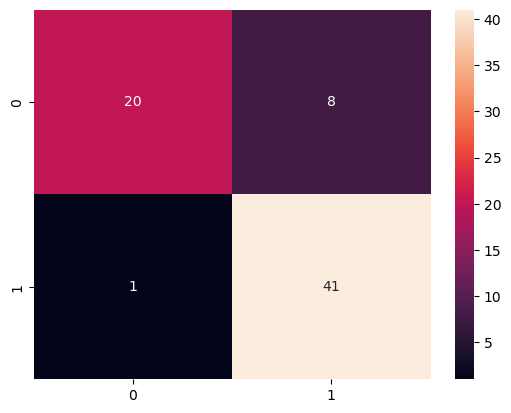

In [98]:
m_confu = confusion_matrix(y2_test, y2_pred_test)
print(m_confu)
import seaborn as sns
sns.heatmap(m_confu, annot=True);

In [100]:
# Accuracy: 
print(f'Accuracy: {accuracy_score(y2_test, y2_pred_test)}')
print(f'Accuracy: {tree_clf_best.score(X2_test, y2_test)}')

# Precision:
print(f'Precision: {precision_score(y2_test, y2_pred_test)}')
precision_score(y2_test, y2_pred_test)

# Recall: 
print(f'Recall: {recall_score(y2_test, y2_pred_test)}')

# F1 score: 
print(f'F1 score: {f1_score(y2_test, y2_pred_test)}')
print()

print(classification_report(y2_test, y2_pred_test))

Accuracy: 0.8714285714285714
Accuracy: 0.8714285714285714
Precision: 0.8367346938775511
Recall: 0.9761904761904762
F1 score: 0.9010989010989012

              precision    recall  f1-score   support

           0       0.95      0.71      0.82        28
           1       0.84      0.98      0.90        42

    accuracy                           0.87        70
   macro avg       0.89      0.85      0.86        70
weighted avg       0.88      0.87      0.87        70

